# AT2 — Previsão de Cancelamento de Clientes (Churn) com MLP

## 1. Contexto do Problema e Dicionário de Dados

**Origem do dataset:** *Telco Customer Churn* (IBM Sample Data), publicado no Kaggle por *blastchar*:
<https://www.kaggle.com/datasets/blastchar/telco-customer-churn>. O arquivo original (`WA_Fn-UseC_-Telco-Customer-Churn.csv`) foi salvo como `data/dataset.csv`.

**Objetivo de negócio:** prever se um cliente de uma operadora de telecomunicações vai **cancelar o serviço (churn)**. Reter um cliente costuma custar bem menos do que conquistar um novo; com a predição, a empresa pode direcionar ações de retenção (descontos, migração de contrato, suporte) aos clientes de maior risco.

**Tipo de problema:** classificação binária (`Churn`: 0 = permanece, 1 = cancelou).

**Colunas utilizadas** (9 preditoras + alvo):

| Coluna | Tipo | Significado prático |
|---|---|---|
| `tenure` | numérica (int) | Meses de permanência do cliente na empresa |
| `MonthlyCharges` | numérica (float) | Valor da mensalidade (US$) |
| `TotalCharges` | numérica (float) | Total já cobrado do cliente (US$) |
| `Contract` | categórica | Tipo de contrato: Month-to-month, One year, Two year |
| `InternetService` | categórica | Serviço de internet: DSL, Fiber optic, No |
| `PaymentMethod` | categórica | Forma de pagamento (4 categorias) |
| `PaperlessBilling` | categórica | Fatura digital: Yes / No |
| `TechSupport` | categórica | Possui suporte técnico: Yes / No / No internet service |
| `OnlineSecurity` | categórica | Possui segurança online: Yes / No / No internet service |
| `Churn` (alvo) | binária | Yes = cancelou, No = permaneceu (convertida para 1/0) |

As demais colunas do arquivo (`customerID`, `gender`, `SeniorCitizen`, `Partner`, etc.) não foram usadas para manter o conjunto de entrada da API enxuto.

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    matthews_corrcoef,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 77

# Funciona tanto se o notebook for executado a partir de notebooks/ quanto da raiz do projeto
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CAMINHO_DADOS = RAIZ / "data" / "dataset.csv"
CAMINHO_MODELO = RAIZ / "models" / "pipeline_rede_neural.joblib"

df = pd.read_csv(CAMINHO_DADOS)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Análise Exploratória Resumida

In [3]:
print("Dimensão original (linhas, colunas):", df.shape)
print("\nValores nulos por coluna (apenas as colunas usadas):")

NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAS = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "TechSupport", "OnlineSecurity"]
ALVO = "Churn"

df = df[NUMERICAS + CATEGORICAS + [ALVO]].copy()
print(df.isna().sum())
print("\nTipos de dados:")
print(df.dtypes)

Dimensão original (linhas, colunas): (7043, 21)

Valores nulos por coluna (apenas as colunas usadas):
tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
InternetService     0
PaymentMethod       0
PaperlessBilling    0
TechSupport         0
OnlineSecurity      0
Churn               0
dtype: int64

Tipos de dados:
tenure                int64
MonthlyCharges      float64
TotalCharges            str
Contract                str
InternetService         str
PaymentMethod           str
PaperlessBilling        str
TechSupport             str
OnlineSecurity          str
Churn                   str
dtype: object


Em `TotalCharges` o arquivo traz espaços em branco (strings vazias) para clientes com `tenure = 0`. Isso faz a coluna ser lida como texto e esconde os nulos. Vamos converter para número e tratar esses registros.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Nulos após conversão numérica de TotalCharges:", df["TotalCharges"].isna().sum())

# Poucos registros (clientes que acabaram de entrar): descartamos
df = df.dropna().reset_index(drop=True)
df[ALVO] = df[ALVO].map({"No": 0, "Yes": 1}).astype(int)

print("Dimensão após limpeza:", df.shape)
df.describe().T

Nulos após conversão numérica de TotalCharges: 11
Dimensão após limpeza: (7032, 10)


,count,mean,std,min,25%,50%,75%,max
tenure,7032.0,32.421786,24.545260,1.00,9.0000,29.000,55.0000,72.00
MonthlyCharges,7032.0,64.798208,30.085974,18.25,35.5875,70.350,89.8625,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.4500,1397.475,3794.7375,8684.80
Churn,7032.0,0.265785,0.441782,0.00,0.0000,0.000,1.0000,1.00


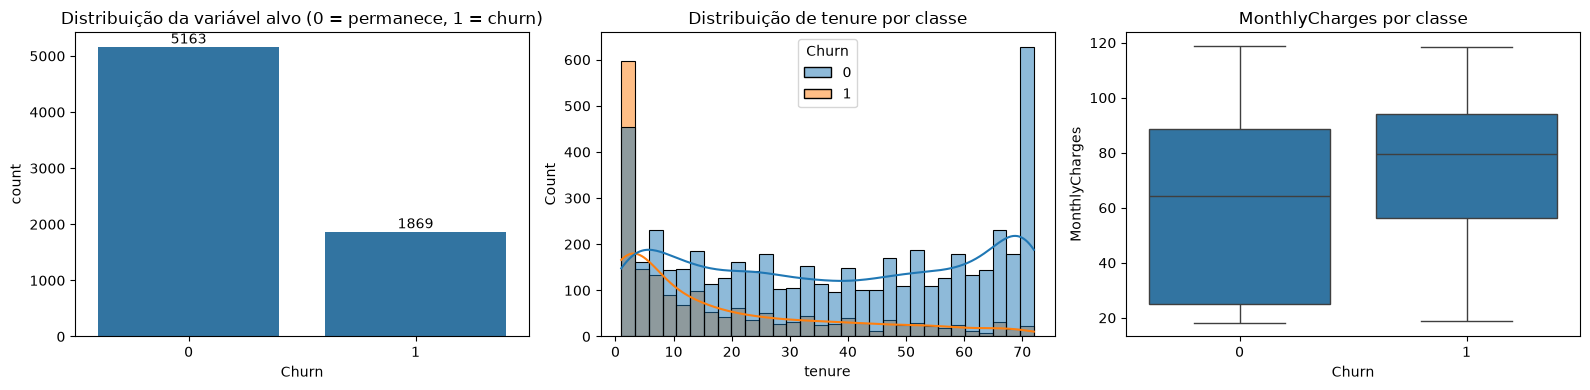

Proporção das classes:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=df, x=ALVO, ax=axes[0])
axes[0].set_title("Distribuição da variável alvo (0 = permanece, 1 = churn)")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

sns.histplot(data=df, x="tenure", hue=ALVO, bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribuição de tenure por classe")

sns.boxplot(data=df, x=ALVO, y="MonthlyCharges", ax=axes[2])
axes[2].set_title("MonthlyCharges por classe")

plt.tight_layout()
plt.show()

print("Proporção das classes:")
print(df[ALVO].value_counts(normalize=True).round(3))

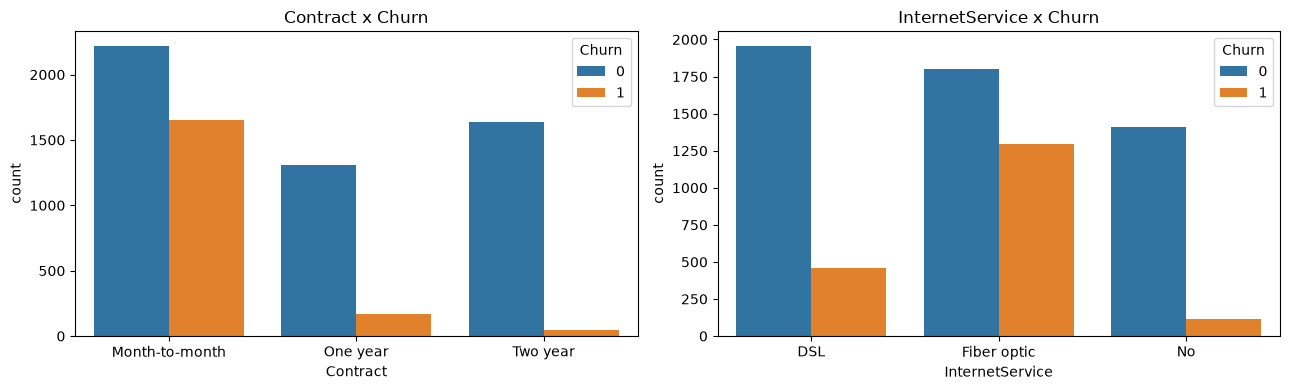

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["Contract", "InternetService"]):
    sns.countplot(data=df, x=col, hue=ALVO, ax=ax)
    ax.set_title(f"{col} x Churn")
plt.tight_layout()
plt.show()

**Observações:** há desbalanceamento moderado (cerca de 73% de clientes que permanecem e 27% de churn), por isso, além da acurácia, vamos olhar o relatório por classe e o coeficiente de Matthews (MCC). Clientes novos (`tenure` baixo) e com contrato mensal tendem a cancelar mais.

## 3. Construção do Pipeline Scikit-Learn

In [7]:
X = df[NUMERICAS + CATEGORICAS]
y = df[ALVO]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)

Treino: (5625, 9) | Teste: (1407, 9)


In [8]:
preprocessador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
    ]
)

mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    alpha=1e-3,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
)

pipeline = Pipeline(steps=[("preprocessamento", preprocessador), ("mlp", mlp)])
pipeline.fit(X_treino, y_treino)
print("Treinamento concluído em", pipeline.named_steps["mlp"].n_iter_, "épocas.")

Treinamento concluído em 25 épocas.


## 4. Avaliação do Modelo

In [9]:
y_pred = pipeline.predict(X_teste)

acuracia = accuracy_score(y_teste, y_pred)
mcc = matthews_corrcoef(y_teste, y_pred)

print(f"Acurácia no teste: {acuracia:.4f}")
print(f"Coeficiente de Matthews (MCC): {mcc:.4f}\n")
print(classification_report(y_teste, y_pred, target_names=["Permanece (0)", "Churn (1)"]))

Acurácia no teste: 0.8038
Coeficiente de Matthews (MCC): 0.4899

               precision    recall  f1-score   support

Permanece (0)       0.86      0.88      0.87      1033
    Churn (1)       0.64      0.61      0.62       374

     accuracy                           0.80      1407
    macro avg       0.75      0.74      0.74      1407
 weighted avg       0.80      0.80      0.80      1407



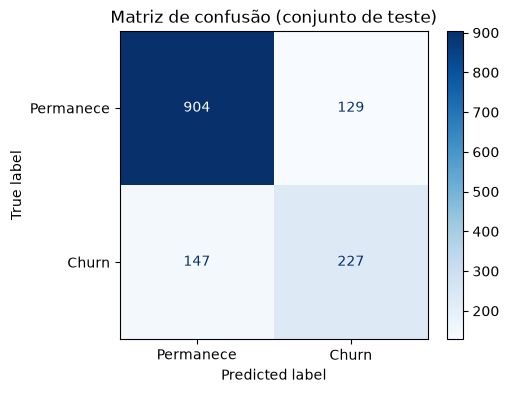

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_teste, y_pred, display_labels=["Permanece", "Churn"], cmap="Blues", ax=ax
)
ax.set_title("Matriz de confusão (conjunto de teste)")
plt.show()

**Interpretação:** os *falsos negativos* (clientes que cancelam mas o modelo previu que ficariam) são o erro mais custoso para o negócio, pois representam oportunidades de retenção perdidas. Os *falsos positivos* geram custo de ações de retenção em clientes que não sairiam. O recall da classe churn e o MCC ajudam a avaliar esse equilíbrio melhor do que a acurácia isolada, dado o desbalanceamento.

## 5. Exportação do Modelo Treinado

O objeto `Pipeline` completo é serializado (e não só a rede) para que a API receba dados brutos e aplique exatamente o mesmo `StandardScaler` e `OneHotEncoder` aprendidos no treino.

In [11]:
CAMINHO_MODELO.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(pipeline, CAMINHO_MODELO)
print("Pipeline salvo em:", CAMINHO_MODELO.relative_to(RAIZ))

Pipeline salvo em: models\pipeline_rede_neural.joblib


In [12]:
# Teste rápido de sanidade: recarrega o arquivo e prediz um registro bruto
modelo_carregado = joblib.load(CAMINHO_MODELO)
exemplo = pd.DataFrame([{
    "tenure": 2, "MonthlyCharges": 95.7, "TotalCharges": 191.4,
    "Contract": "Month-to-month", "InternetService": "Fiber optic",
    "PaymentMethod": "Electronic check", "PaperlessBilling": "Yes",
    "TechSupport": "No", "OnlineSecurity": "No",
}])
print("Classes:", modelo_carregado.classes_)
print("Probabilidades:", modelo_carregado.predict_proba(exemplo).round(3))

Classes: [0 1]
Probabilidades: [[0.154 0.846]]
